# ProductPulse
### Evidence-Driven Product Investigation & Decision Engine

## Project Overview

ProductPulse is a data analytics project designed to investigate user behaviour, identify potential product performance issues, and prioritize areas that require further investigation.

Using real-world e-commerce event data, the project analyses how users interact with products through views, add-to-cart actions, and transactions.

Rather than stopping at descriptive analytics, ProductPulse aims to transform observed patterns into structured investigation candidates and evidence-based recommendations.

## Business Objectives

- Analyse user engagement and product interaction patterns.
- Examine the relationship between product views, cart activity, and transactions.
- Identify unusual activity patterns and potential product performance issues.
- Investigate category-level and product-level behaviour.
- Develop a prioritization framework to rank investigation candidates.
- Present actionable insights to support product and business decisions.

## Key Business Questions

1. How do users interact with products across different event types?
2. What patterns exist between product views, cart activity, and transactions?
3. Which product categories demonstrate unusually low downstream activity?
4. Are there temporal anomalies in user engagement or transaction activity?
5. Which identified issues should a product team investigate first?

## Tools & Technologies

Python | Pandas | NumPy | Matplotlib | Seaborn | Google Colab

## Analytical Approach

The project follows a structured analytical workflow:

**Data Collection → Data Validation → Exploratory Analysis → Behavioural Analysis → Anomaly Investigation → Prioritization → Business Recommendations**

## Important Note

This project uses observational event data. Identified patterns indicate potential areas for investigation and do not independently establish causation, revenue impact, or the underlying reason for user behaviour.

# 1. Dataset Overview

## Data Source

ProductPulse uses the publicly available **Retailrocket E-commerce Dataset**.

[Dataset source — Kaggle](https://www.kaggle.com/datasets/retailrocket/ecommerce-dataset)

The dataset contains user interaction events, historical product properties, and product category relationships.

## Files Used

| Dataset | Description |
|---|---|
| `events.csv` | Records user interactions with products |
| `category_tree.csv` | Contains product category and parent-category relationships |
| `item_properties_part1.csv` | Historical product property records |
| `item_properties_part2.csv` | Additional historical product property records |

## Important Columns

### Events Dataset

| Column | Description |
|---|---|
| `timestamp` | Time at which an event occurred |
| `visitorid` | Visitor identifier |
| `event` | Interaction type |
| `itemid` | Product identifier |
| `transactionid` | Transaction identifier, where recorded |

### Item Properties Dataset

| Column | Description |
|---|---|
| `timestamp` | Time of the property record |
| `itemid` | Product identifier |
| `property` | Property name |
| `value` | Recorded property value |

### Category Tree

| Column | Description |
|---|---|
| `categoryid` | Category identifier |
| `parentid` | Parent category identifier |

## Event Types

- **View:** A visitor views a product.
- **Add to cart:** A visitor adds a product to their cart.
- **Transaction:** A transaction event is recorded.

## Observation Period

The event dataset covers May 3, 2015, to September 18, 2015.

## Analytical Scope

The project examines visitor behaviour, product engagement, category-level activity, temporal patterns, and potential anomalies.

Historical item properties are particularly important because product-category assignments can change over time. The analysis therefore considers category history rather than assuming that every product has one permanent category.

# 2. Data Loading & Environment Setup

## Connecting Google Drive

Google Colab is used as the development environment, while the datasets are stored in Google Drive.

Mounting Google Drive allows the notebook to access the dataset files without manually uploading them every time the notebook is opened.

## Dataset Loading Strategy

The original datasets are loaded into separate DataFrames to preserve the source data.

An independent working copy of the events dataset is created for analysis. This allows transformations such as timestamp conversion and feature engineering without modifying the original dataset.

The event dataset is loaded using Python's CSV parsing engine to ensure the complete dataset is read correctly.

The item property datasets are loaded with `low_memory=False` to improve data type inference across large files.

## Data Preparation Approach

The workflow follows three principles:

1. Preserve original datasets.
2. Create separate analytical copies before transformations.
3. Validate dataset dimensions, columns, data types, and records after loading.

The following cells implement the environment setup and dataset loading process.

In [55]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [56]:
import os

DATA_DIR = "/content/drive/MyDrive/productpulse/data"

print("Checking ProductPulse data folder...\n")

if os.path.exists(DATA_DIR):
    files = sorted(os.listdir(DATA_DIR))

    for file in files:
        file_path = os.path.join(DATA_DIR, file)
        size_mb = os.path.getsize(file_path) / (1024 ** 2)
        print(f"{file:<40} {size_mb:.2f} MB")

    print(f"\nTotal files found: {len(files)}")
else:
    print("ERROR: Data folder not found.")

Checking ProductPulse data folder...

category_tree.csv                        0.01 MB
events.csv                               89.87 MB
item_properties_part1.csv                461.88 MB
item_properties_part2.csv                389.99 MB

Total files found: 4


In [57]:
import pandas as pd

EVENTS_PATH = f"{DATA_DIR}/events.csv"

print("Loading events dataset...")

events_master_raw = pd.read_csv(
    EVENTS_PATH,
    engine="python"
)

print("\nDataset loaded successfully!")
print("Shape:", events_master_raw.shape)
print("\nColumns:")
print(events_master_raw.columns.tolist())

print("\nFirst 5 rows:")
display(events_master_raw.head())

print("\nEvent distribution:")
print(events_master_raw["event"].value_counts())

print("\nMissing values:")
print(events_master_raw.isnull().sum())

Loading events dataset...

Dataset loaded successfully!
Shape: (2756101, 5)

Columns:
['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']

First 5 rows:


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN



Event distribution:
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64

Missing values:
timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    2733644
dtype: int64


In [58]:
# Create a separate working copy
events = events_master_raw.copy()

# Convert Unix timestamp (milliseconds) into datetime
events["timestamp"] = pd.to_datetime(
    events["timestamp"],
    unit="ms"
)

# Extract date and hour for time-based analysis
events["date"] = events["timestamp"].dt.date
events["hour"] = events["timestamp"].dt.hour

# Validation
print("Analysis dataset shape:", events.shape)

print("\nData types:")
print(events.dtypes)

print("\nDate range:")
print("Start:", events["timestamp"].min())
print("End:", events["timestamp"].max())

print("\nUnique visitors:", events["visitorid"].nunique())
print("Unique items:", events["itemid"].nunique())
print("Unique dates:", events["date"].nunique())

print("\nSample transformed data:")
display(events.head())

Analysis dataset shape: (2756101, 7)

Data types:
timestamp        datetime64[ns]
visitorid                 int64
event                    object
itemid                    int64
transactionid           float64
date                     object
hour                      int32
dtype: object

Date range:
Start: 2015-05-03 03:00:04.384000
End: 2015-09-18 02:59:47.788000

Unique visitors: 1407580
Unique items: 235061
Unique dates: 139

Sample transformed data:


,timestamp,visitorid,event,itemid,transactionid,date,hour
0,2015-06-02 05:02:12.117,257597,view,355908,NaN,2015-06-02,5
1,2015-06-02 05:50:14.164,992329,view,248676,NaN,2015-06-02,5
2,2015-06-02 05:13:19.827,111016,view,318965,NaN,2015-06-02,5
3,2015-06-02 05:12:35.914,483717,view,253185,NaN,2015-06-02,5
4,2015-06-02 05:02:17.106,951259,view,367447,NaN,2015-06-02,5


In [59]:
# 1. Confirm the original dataset is unchanged
assert events_master_raw.shape == (2756101, 5)

# 2. Confirm no rows were lost or added
assert len(events) == len(events_master_raw)

# 3. Confirm timestamp conversion is correct
expected_timestamps = pd.to_datetime(
    events_master_raw["timestamp"],
    unit="ms"
)

assert events["timestamp"].equals(expected_timestamps)

# 4. Confirm original non-timestamp columns are unchanged
for column in ["visitorid", "event", "itemid", "transactionid"]:
    assert events[column].equals(events_master_raw[column])

# 5. Confirm derived columns are correct
assert events["date"].equals(events["timestamp"].dt.date)
assert events["hour"].equals(events["timestamp"].dt.hour)

# 6. Confirm there are no invalid timestamps
assert events["timestamp"].notna().all()

print("ALL DATA INTEGRITY CHECKS PASSED!")
print("Original records preserved.")
print("Timestamp conversion verified.")
print("Derived date and hour columns verified.")

ALL DATA INTEGRITY CHECKS PASSED!
Original records preserved.
Timestamp conversion verified.
Derived date and hour columns verified.


In [60]:
CATEGORY_PATH = f"{DATA_DIR}/category_tree.csv"

category_tree_raw = pd.read_csv(CATEGORY_PATH)

print("Dataset loaded successfully!")
print("\nShape:", category_tree_raw.shape)

print("\nColumns:")
print(category_tree_raw.columns.tolist())

print("\nData types:")
print(category_tree_raw.dtypes)

print("\nFirst 10 rows:")
display(category_tree_raw.head(10))

print("\nMissing values:")
print(category_tree_raw.isnull().sum())

print("\nDuplicate rows:", category_tree_raw.duplicated().sum())

Dataset loaded successfully!

Shape: (1669, 2)

Columns:
['categoryid', 'parentid']

Data types:
categoryid      int64
parentid      float64
dtype: object

First 10 rows:


,categoryid,parentid
0,1016,213.0
1,809,169.0
2,570,9.0
3,1691,885.0
4,536,1691.0
5,231,NaN
6,542,378.0
7,1146,542.0
8,1140,542.0
9,1479,1537.0



Missing values:
categoryid     0
parentid      25
dtype: int64

Duplicate rows: 0


In [61]:
# Check category ID uniqueness
print("Unique category IDs:", category_tree_raw["categoryid"].nunique())
print("Total category rows:", len(category_tree_raw))

# Identify root categories (no parent)
root_categories = category_tree_raw[
    category_tree_raw["parentid"].isna()
]

print("\nRoot categories:", len(root_categories))

# Check whether all non-null parent IDs exist as category IDs
known_categories = set(category_tree_raw["categoryid"])

parent_ids = set(
    category_tree_raw["parentid"].dropna().astype(int)
)

missing_parents = parent_ids - known_categories

print("Parent IDs not found in category IDs:", len(missing_parents))
print("Missing parent IDs:", sorted(missing_parents))

# Display root categories
print("\nRoot category records:")
display(root_categories)

Unique category IDs: 1669
Total category rows: 1669

Root categories: 25
Parent IDs not found in category IDs: 0
Missing parent IDs: []

Root category records:


,categoryid,parentid
5,231,NaN
589,791,NaN
861,1490,NaN
939,431,NaN
1111,755,NaN
1142,378,NaN
1208,1579,NaN
1211,1394,NaN
1322,659,NaN
1329,1057,NaN


In [62]:
ITEM_PROPERTIES_1_PATH = f"{DATA_DIR}/item_properties_part1.csv"

print("Loading item_properties_part1.csv...")

item_properties_1_raw = pd.read_csv(
    ITEM_PROPERTIES_1_PATH,
    low_memory=False
)

print("\nDataset loaded successfully!")
print("Shape:", item_properties_1_raw.shape)

print("\nColumns:")
print(item_properties_1_raw.columns.tolist())

print("\nData types:")
print(item_properties_1_raw.dtypes)

print("\nFirst 5 rows:")
display(item_properties_1_raw.head())

print("\nMissing values:")
print(item_properties_1_raw.isnull().sum())

Loading item_properties_part1.csv...

Dataset loaded successfully!
Shape: (10999999, 4)

Columns:
['timestamp', 'itemid', 'property', 'value']

Data types:
timestamp     int64
itemid        int64
property     object
value        object
dtype: object

First 5 rows:


,timestamp,itemid,property,value
0,1435460400000,460429,categoryid,1338
1,1441508400000,206783,888,1116713 960601 n277.200
2,1439089200000,395014,400,n552.000 639502 n720.000 424566
3,1431226800000,59481,790,n15360.000
4,1431831600000,156781,917,828513



Missing values:
timestamp    0
itemid       0
property     0
value        0
dtype: int64


In [63]:
ITEM_PROPERTIES_2_PATH = f"{DATA_DIR}/item_properties_part2.csv"

print("Loading item_properties_part2.csv...")

item_properties_2_raw = pd.read_csv(
    ITEM_PROPERTIES_2_PATH,
    low_memory=False
)

print("\nDataset loaded successfully!")
print("Shape:", item_properties_2_raw.shape)

print("\nColumns:")
print(item_properties_2_raw.columns.tolist())

print("\nData types:")
print(item_properties_2_raw.dtypes)

print("\nFirst 5 rows:")
display(item_properties_2_raw.head())

print("\nMissing values:")
print(item_properties_2_raw.isnull().sum())

Loading item_properties_part2.csv...

Dataset loaded successfully!
Shape: (9275903, 4)

Columns:
['timestamp', 'itemid', 'property', 'value']

Data types:
timestamp     int64
itemid        int64
property     object
value        object
dtype: object

First 5 rows:


,timestamp,itemid,property,value
0,1433041200000,183478,561,769062
1,1439694000000,132256,976,n26.400 1135780
2,1435460400000,420307,921,1149317 1257525
3,1431831600000,403324,917,1204143
4,1435460400000,230701,521,769062



Missing values:
timestamp    0
itemid       0
property     0
value        0
dtype: int64


In [64]:
# Extract category records from each properties dataset
category_part1 = item_properties_1_raw.loc[
    item_properties_1_raw["property"] == "categoryid"
].copy()

category_part2 = item_properties_2_raw.loc[
    item_properties_2_raw["property"] == "categoryid"
].copy()

print("Category records extracted:")
print("Part 1:", category_part1.shape)
print("Part 2:", category_part2.shape)

# Combine the extracted records
category_history_raw = pd.concat(
    [category_part1, category_part2],
    ignore_index=True
)

print("\nCombined category history:")
print("Shape:", category_history_raw.shape)

print("\nUnique items:", category_history_raw["itemid"].nunique())

print("\nMissing values:")
print(category_history_raw.isnull().sum())

print("\nSample records:")
display(category_history_raw.head())

# Check category values are numeric
category_history_raw["value"] = pd.to_numeric(
    category_history_raw["value"],
    errors="coerce"
)

print("\nNon-numeric category values:", category_history_raw["value"].isna().sum())

Category records extracted:
Part 1: (426305, 4)
Part 2: (361909, 4)

Combined category history:
Shape: (788214, 4)

Unique items: 417053

Missing values:
timestamp    0
itemid       0
property     0
value        0
dtype: int64

Sample records:


,timestamp,itemid,property,value
0,1435460400000,460429,categoryid,1338
1,1432436400000,281245,categoryid,1277
2,1435460400000,35575,categoryid,1059
3,1437274800000,8313,categoryid,1147
4,1437879600000,55102,categoryid,47



Non-numeric category values: 0


In [65]:
# Convert category values to integer IDs
category_history_raw["value"] = category_history_raw["value"].astype("int64")

# Check category IDs against the category tree
known_categories = set(category_tree_raw["categoryid"])

observed_categories = set(category_history_raw["value"])

unknown_categories = observed_categories - known_categories

print("CATEGORY REFERENCE VALIDATION")
print("--------------------------------")
print("Unique category IDs in history:", len(observed_categories))
print("Categories in category tree:", len(known_categories))
print("Unknown category IDs:", len(unknown_categories))

# Check historical category changes per item
categories_per_item = (
    category_history_raw
    .groupby("itemid")["value"]
    .nunique()
)

items_with_multiple_categories = categories_per_item[
    categories_per_item > 1
]

print("\nCATEGORY HISTORY VALIDATION")
print("--------------------------------")
print("Unique items:", category_history_raw["itemid"].nunique())
print("Items with multiple category IDs:", len(items_with_multiple_categories))
print("Items with one category ID:", (categories_per_item == 1).sum())

# Check duplicate item-timestamp-category records
duplicate_records = category_history_raw.duplicated(
    subset=["timestamp", "itemid", "value"]
).sum()

print("Duplicate item-timestamp-category records:", duplicate_records)

CATEGORY REFERENCE VALIDATION
--------------------------------
Unique category IDs in history: 1242
Categories in category tree: 1669
Unknown category IDs: 30

CATEGORY HISTORY VALIDATION
--------------------------------
Unique items: 417053
Items with multiple category IDs: 23352
Items with one category ID: 393701
Duplicate item-timestamp-category records: 0


In [66]:
# Identify category IDs absent from the category tree
known_categories = set(category_tree_raw["categoryid"])

unknown_categories = sorted(
    set(category_history_raw["value"]) - known_categories
)

print("Unknown category IDs:")
print(unknown_categories)

# Inspect their frequency
unknown_category_records = (
    category_history_raw[
        category_history_raw["value"].isin(unknown_categories)
    ]
    .groupby("value")
    .agg(
        record_count=("itemid", "size"),
        unique_items=("itemid", "nunique")
    )
    .sort_values("record_count", ascending=False)
    .reset_index()
)

print("\nUnknown category frequency:")
display(unknown_category_records)

print("\nTotal records with unknown categories:",
      len(category_history_raw[
          category_history_raw["value"].isin(unknown_categories)
      ]))

Unknown category IDs:
[80, 168, 171, 181, 280, 300, 306, 307, 345, 347, 462, 554, 566, 721, 899, 919, 930, 974, 1046, 1062, 1123, 1158, 1319, 1428, 1446, 1538, 1571, 1594, 1597, 1602]

Unknown category frequency:


,value,record_count,unique_items
0,306,91,61
1,347,10,10
2,1062,8,8
3,919,8,8
4,1446,7,7
5,1046,6,6
6,181,5,5
7,554,3,3
8,462,3,3
9,974,3,3



Total records with unknown categories: 167


In [67]:
# Create a separate analytical copy
category_history = category_history_raw.copy()

# Convert timestamp
category_history["timestamp"] = pd.to_datetime(
    category_history["timestamp"],
    unit="ms"
)

# Rename value to category_id for clarity
category_history = category_history.rename(
    columns={"value": "category_id"}
)

# Flag category IDs that exist in the category tree
known_categories = set(category_tree_raw["categoryid"])

category_history["category_exists_in_tree"] = (
    category_history["category_id"].isin(known_categories)
)

# Validation summary
print("FINAL CATEGORY HISTORY")
print("----------------------")
print("Shape:", category_history.shape)
print("Unique items:", category_history["itemid"].nunique())
print("Unique categories:", category_history["category_id"].nunique())

print("\nCategory tree matching:")
print(category_history["category_exists_in_tree"].value_counts())

print("\nDate range:")
print("Start:", category_history["timestamp"].min())
print("End:", category_history["timestamp"].max())

print("\nFirst 5 rows:")
display(category_history.head())

FINAL CATEGORY HISTORY
----------------------
Shape: (788214, 5)
Unique items: 417053
Unique categories: 1242

Category tree matching:
category_exists_in_tree
True     788047
False       167
Name: count, dtype: int64

Date range:
Start: 2015-05-10 03:00:00
End: 2015-09-13 03:00:00

First 5 rows:


,timestamp,itemid,property,category_id,category_exists_in_tree
0,2015-06-28 03:00:00,460429,categoryid,1338,True
1,2015-05-24 03:00:00,281245,categoryid,1277,True
2,2015-06-28 03:00:00,35575,categoryid,1059,True
3,2015-07-19 03:00:00,8313,categoryid,1147,True
4,2015-07-26 03:00:00,55102,categoryid,47,True


# 3. Data Validation & Integrity Checks

Before conducting exploratory analysis, the datasets are validated to ensure that the analytical foundation is reliable.

## Validation Objectives

- Verify that all datasets have been loaded with the expected dimensions.
- Check for missing values and duplicate records.
- Validate category identifiers against the category tree.
- Identify products with multiple historical category assignments.
- Confirm timestamp conversions and derived date fields.
- Ensure that the original event records remain unchanged.

## Data Integrity Approach

The original events dataset is preserved separately from the analytical working copy.

Assertions are used to verify row counts, timestamp transformations, and the preservation of original columns.

Historical category records are also checked for duplicate assignments and category IDs that do not exist in the category tree.

## Validation Results

The following code performs consolidated checks across the loaded datasets and reports whether the data foundation passes the defined integrity conditions.

In [68]:
# PRODUCTPULSE — DATA FOUNDATION VALIDATION

print("=" * 55)
print("          PRODUCTPULSE DATA VALIDATION")
print("=" * 55)

# Dataset shapes
datasets = {
    "Events (Original)": events_master_raw,
    "Events (Analysis)": events,
    "Category Tree": category_tree_raw,
    "Item Properties Part 1": item_properties_1_raw,
    "Item Properties Part 2": item_properties_2_raw,
    "Category History": category_history
}

print("\n1. DATASET SHAPES")
print("-" * 55)

for name, df in datasets.items():
    print(f"{name:<30} {df.shape}")

# Critical integrity checks
print("\n2. INTEGRITY CHECKS")
print("-" * 55)

checks = {
    "Original events row count": len(events_master_raw) == 2756101,
    "Analysis events row count": len(events) == 2756101,
    "Category tree row count": len(category_tree_raw) == 1669,
    "Properties Part 1 row count": len(item_properties_1_raw) == 10999999,
    "Properties Part 2 row count": len(item_properties_2_raw) == 9275903,
    "Category history row count": len(category_history) == 788214,
    "All event timestamps valid": events["timestamp"].notna().all(),
    "All category-history timestamps valid": category_history["timestamp"].notna().all(),
    "No missing category-history IDs": category_history["category_id"].notna().all(),
    "Original events preserved": events_master_raw["timestamp"].equals(
        pd.to_numeric(events["timestamp"].astype("int64") // 10**6)
    )
}

for check, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'} | {check}")

print("\n3. FINAL RESULT")
print("-" * 55)

if all(checks.values()):
    print("ALL VALIDATION CHECKS PASSED.")
    print("ProductPulse data foundation is ready.")
else:
    print("VALIDATION FAILURE: Investigate failed checks before proceeding.")

          PRODUCTPULSE DATA VALIDATION

1. DATASET SHAPES
-------------------------------------------------------
Events (Original)              (2756101, 5)
Events (Analysis)              (2756101, 7)
Category Tree                  (1669, 2)
Item Properties Part 1         (10999999, 4)
Item Properties Part 2         (9275903, 4)
Category History               (788214, 5)

2. INTEGRITY CHECKS
-------------------------------------------------------
PASS | Original events row count
PASS | Analysis events row count
PASS | Category tree row count
PASS | Properties Part 1 row count
PASS | Properties Part 2 row count
PASS | Category history row count
PASS | All event timestamps valid
PASS | All category-history timestamps valid
PASS | No missing category-history IDs
PASS | Original events preserved

3. FINAL RESULT
-------------------------------------------------------
ALL VALIDATION CHECKS PASSED.
ProductPulse data foundation is ready.


# 4. Exploratory Data Analysis (EDA)

## Event Distribution

This section examines the overall distribution of user interactions across three event types: views, add-to-cart actions, and transactions.

The analysis establishes a baseline understanding of platform activity by examining:
- Total events and their relative distribution.
- Unique visitors associated with each event type.
- Unique products involved in each type of interaction.

**Business purpose:** Understand the platform's interaction mix and identify where user activity is concentrated before investigating deeper behavioural patterns.

**Interpretation note:** Event distribution provides an overview of activity, not a sequential conversion funnel. Event counts alone do not establish how users move through the purchase journey.

In [69]:
# PRODUCTPULSE — EVENT DISTRIBUTION

event_summary = (
    events.groupby("event")
    .agg(
        total_events=("event", "size"),
        unique_visitors=("visitorid", "nunique"),
        unique_items=("itemid", "nunique")
    )
    .reset_index()
)

event_summary["event_share_pct"] = (
    event_summary["total_events"] /
    event_summary["total_events"].sum() * 100
).round(2)

event_summary = event_summary.sort_values(
    "total_events",
    ascending=False
)

display(event_summary)

,event,total_events,unique_visitors,unique_items,event_share_pct
2,view,2664312,1404179,234838,96.67
0,addtocart,69332,37722,23903,2.52
1,transaction,22457,11719,12025,0.81


# 5. User Behaviour Analysis

This section examines how visitors interact with the platform across views, add-to-cart actions, and transactions.

The analysis covers:
- **Visitor segmentation:** Group visitors based on the types of events they generated.
- **Cart and transaction overlap:** Examine how many visitors and visitor-product pairs have both cart and transaction activity.
- **Event sequence:** Compare the timing of first cart and first transaction events for matched visitor-product pairs.
- **Purchase delay:** Measure the time between the first cart event and first transaction event.

**Business purpose:** Understand observed patterns in user engagement and purchasing behaviour, and identify areas that may warrant further investigation.

**Interpretation note:** Visitor-level event overlap is not a sequential conversion funnel. Cart activity without a matched transaction does not automatically mean cart abandonment. Likewise, temporal order and association do not establish causation.

In [70]:
# PRODUCTPULSE — VISITOR BEHAVIOUR MATRIX

visitor_events = (
    events.pivot_table(
        index="visitorid",
        columns="event",
        values="itemid",
        aggfunc="size",
        fill_value=0
    )
)

# Ensure all three event columns exist
visitor_events = visitor_events.reindex(
    columns=["view", "addtocart", "transaction"],
    fill_value=0
)

# Convert event counts into Boolean indicators
visitor_flags = visitor_events.gt(0)

print("Total unique visitors:", len(visitor_flags))

print("\nVisitors participating in each event:")
for event in ["view", "addtocart", "transaction"]:
    count = visitor_flags[event].sum()
    percentage = count / len(visitor_flags) * 100

    print(f"{event:<15} {count:>10,} ({percentage:.2f}%)")

Total unique visitors: 1407580

Visitors participating in each event:
view             1,404,179 (99.76%)
addtocart           37,722 (2.68%)
transaction         11,719 (0.83%)


In [71]:
# PRODUCTPULSE — MUTUALLY EXCLUSIVE VISITOR SEGMENTS

conditions = [
    visitor_flags["view"] & ~visitor_flags["addtocart"] & ~visitor_flags["transaction"],
    visitor_flags["view"] & visitor_flags["addtocart"] & ~visitor_flags["transaction"],
    visitor_flags["view"] & visitor_flags["addtocart"] & visitor_flags["transaction"],
    visitor_flags["view"] & ~visitor_flags["addtocart"] & visitor_flags["transaction"],
    ~visitor_flags["view"] & visitor_flags["addtocart"] & ~visitor_flags["transaction"],
    ~visitor_flags["view"] & visitor_flags["addtocart"] & visitor_flags["transaction"],
    ~visitor_flags["view"] & ~visitor_flags["addtocart"] & visitor_flags["transaction"]
]

segments = [
    "View only",
    "View + Cart, no Transaction",
    "View + Cart + Transaction",
    "View + Transaction, no Cart",
    "Cart only",
    "Cart + Transaction, no View",
    "Transaction only"
]

visitor_flags["visitor_segment"] = "Unclassified"

for condition, segment in zip(conditions, segments):
    visitor_flags.loc[condition, "visitor_segment"] = segment

segment_summary = (
    visitor_flags["visitor_segment"]
    .value_counts()
    .rename_axis("visitor_segment")
    .reset_index(name="unique_visitors")
)

segment_summary["visitor_share_pct"] = (
    segment_summary["unique_visitors"] /
    len(visitor_flags) * 100
).round(2)

display(segment_summary)

print("\nTotal classified visitors:",
      segment_summary["unique_visitors"].sum())

print("Unclassified visitors:",
      (visitor_flags["visitor_segment"] == "Unclassified").sum())

,visitor_segment,unique_visitors,visitor_share_pct
0,View only,1368715,97.24
1,"View + Cart, no Transaction",24173,1.72
2,View + Cart + Transaction,10228,0.73
3,Cart only,2973,0.21
4,"View + Transaction, no Cart",1063,0.08
5,"Cart + Transaction, no View",348,0.02
6,Transaction only,80,0.01



Total classified visitors: 1407580
Unclassified visitors: 0


In [72]:
# PRODUCTPULSE — CART AND TRANSACTION OVERLAP

cart_visitors = visitor_flags["addtocart"].sum()

cart_and_transaction = (
    visitor_flags["addtocart"] &
    visitor_flags["transaction"]
).sum()

cart_without_transaction = (
    visitor_flags["addtocart"] &
    ~visitor_flags["transaction"]
).sum()

cart_transaction_ratio = (
    cart_and_transaction / cart_visitors * 100
)

print("Visitors with cart activity:", f"{cart_visitors:,}")
print("Visitors with both cart and transaction:",
      f"{cart_and_transaction:,}")
print("Visitors with cart but no transaction:",
      f"{cart_without_transaction:,}")

print("\nCart-to-transaction visitor overlap:",
      f"{cart_transaction_ratio:.2f}%")

print("Cart visitors without recorded transaction:",
      f"{100 - cart_transaction_ratio:.2f}%")

Visitors with cart activity: 37,722
Visitors with both cart and transaction: 10,576
Visitors with cart but no transaction: 27,146

Cart-to-transaction visitor overlap: 28.04%
Cart visitors without recorded transaction: 71.96%


In [73]:
# PRODUCTPULSE — VISITOR-PRODUCT EVENT OVERLAP

cart_pairs = (
    events.loc[
        events["event"] == "addtocart",
        ["visitorid", "itemid"]
    ]
    .drop_duplicates()
)

transaction_pairs = (
    events.loc[
        events["event"] == "transaction",
        ["visitorid", "itemid"]
    ]
    .drop_duplicates()
)

# Match visitor and item combinations
matched_pairs = cart_pairs.merge(
    transaction_pairs,
    on=["visitorid", "itemid"],
    how="inner"
)

# Unique cart visitor-item combinations
total_cart_pairs = len(cart_pairs)

# Unique cart pairs with a matching transaction
matched_cart_pairs = len(matched_pairs)

print("Unique visitor-product cart pairs:", f"{total_cart_pairs:,}")
print("Pairs with matching transaction:", f"{matched_cart_pairs:,}")
print(
    "Pairs without matching transaction:",
    f"{total_cart_pairs - matched_cart_pairs:,}"
)

print(
    "\nVisitor-product overlap percentage:",
    f"{matched_cart_pairs / total_cart_pairs * 100:.2f}%"
)

Unique visitor-product cart pairs: 62,025
Pairs with matching transaction: 19,045
Pairs without matching transaction: 42,980

Visitor-product overlap percentage: 30.71%


In [74]:
# PRODUCTPULSE — TEMPORAL VISITOR-PRODUCT ANALYSIS

cart_times = (
    events[events["event"] == "addtocart"]
    .groupby(["visitorid", "itemid"])["timestamp"]
    .min()
    .reset_index(name="first_cart_time")
)

transaction_times = (
    events[events["event"] == "transaction"]
    .groupby(["visitorid", "itemid"])["timestamp"]
    .min()
    .reset_index(name="first_transaction_time")
)

# Match visitor-product pairs
temporal_pairs = cart_times.merge(
    transaction_times,
    on=["visitorid", "itemid"],
    how="inner"
)

# Check whether the first cart occurred before the first transaction
temporal_pairs["cart_before_transaction"] = (
    temporal_pairs["first_cart_time"] <
    temporal_pairs["first_transaction_time"]
)

temporal_pairs["same_timestamp"] = (
    temporal_pairs["first_cart_time"] ==
    temporal_pairs["first_transaction_time"]
)

print("Matched visitor-product pairs:", len(temporal_pairs))

print("\nTemporal sequence:")
print(
    temporal_pairs["cart_before_transaction"]
    .value_counts()
    .rename(index={True: "Cart before transaction", False: "Cart not before transaction"})
)

print("\nSame timestamp:", temporal_pairs["same_timestamp"].sum())

print(
    "\nPercentage with cart before transaction:",
    f"{temporal_pairs['cart_before_transaction'].mean() * 100:.2f}%"
)

Matched visitor-product pairs: 19045

Temporal sequence:
cart_before_transaction
Cart before transaction        18942
Cart not before transaction      103
Name: count, dtype: int64

Same timestamp: 0

Percentage with cart before transaction: 99.46%


In [75]:
# PRODUCTPULSE — TIME BETWEEN FIRST CART AND FIRST TRANSACTION

valid_temporal_pairs = temporal_pairs[
    temporal_pairs["cart_before_transaction"]
].copy()

valid_temporal_pairs["time_to_transaction_hours"] = (
    valid_temporal_pairs["first_transaction_time"] -
    valid_temporal_pairs["first_cart_time"]
).dt.total_seconds() / 3600

print("Valid temporal pairs:", len(valid_temporal_pairs))

print("\nTime to transaction summary (hours):")
display(
    valid_temporal_pairs["time_to_transaction_hours"]
    .describe()
    .round(2)
)

print("\nMedian time to transaction (hours):",
      round(valid_temporal_pairs["time_to_transaction_hours"].median(), 2))

Valid temporal pairs: 18942

Time to transaction summary (hours):


,time_to_transaction_hours
count,18942.00
mean,6.23
std,62.82
min,0.00
25%,0.04
50%,0.08
75%,0.21
max,2208.52



Median time to transaction (hours): 0.08


In [76]:
# PRODUCTPULSE — PURCHASE DELAY DISTRIBUTION

delay = valid_temporal_pairs["time_to_transaction_hours"]

thresholds = {
    "Within 5 minutes": 5 / 60,
    "Within 15 minutes": 0.25,
    "Within 1 hour": 1,
    "Within 24 hours": 24,
    "Within 7 days": 168,
    "More than 7 days": float("inf")
}

delay_summary = []

for label, threshold in thresholds.items():

    if label == "More than 7 days":
        count = (delay > 168).sum()

    elif label == "Within 5 minutes":
        count = (delay <= threshold).sum()

    else:
        count = (delay <= threshold).sum()

    delay_summary.append({
        "time_threshold": label,
        "visitor_product_pairs": count,
        "percentage": round(count / len(delay) * 100, 2)
    })

delay_summary_df = pd.DataFrame(delay_summary)

display(delay_summary_df)

,time_threshold,visitor_product_pairs,percentage
0,Within 5 minutes,9966,52.61
1,Within 15 minutes,14728,77.75
2,Within 1 hour,17075,90.14
3,Within 24 hours,18424,97.27
4,Within 7 days,18776,99.12
5,More than 7 days,166,0.88


In [77]:
# PRODUCTPULSE — EXTREME PURCHASE DELAYS

long_delay_pairs = (
    valid_temporal_pairs[
        valid_temporal_pairs["time_to_transaction_hours"] > 168
    ]
    .sort_values(
        "time_to_transaction_hours",
        ascending=False
    )
    .copy()
)

print("Pairs with delays exceeding 7 days:", len(long_delay_pairs))

print("\nLongest 10 observed delays:")
display(
    long_delay_pairs[
        [
            "visitorid",
            "itemid",
            "first_cart_time",
            "first_transaction_time",
            "time_to_transaction_hours"
        ]
    ].head(10)
)

print("\nDelay statistics for these pairs:")
display(
    long_delay_pairs["time_to_transaction_hours"]
    .describe()
    .round(2)
)

Pairs with delays exceeding 7 days: 166

Longest 10 observed delays:


,visitorid,itemid,first_cart_time,first_transaction_time,time_to_transaction_hours
16978,1229029,181550,2015-05-19 22:39:31.584,2015-08-19 23:10:28.522,2208.515816
16977,1229029,125799,2015-05-19 23:18:31.088,2015-08-19 23:10:28.490,2207.865945
12333,899857,245707,2015-05-12 14:59:12.699,2015-08-03 14:12:31.509,1991.221892
7198,530559,338660,2015-06-16 16:25:36.143,2015-09-04 01:33:36.001,1905.133294
8883,672785,421606,2015-05-05 19:18:55.363,2015-07-13 14:59:21.356,1651.673887
16779,1210136,176669,2015-06-03 21:30:19.055,2015-08-07 23:32:37.977,1562.038589
16783,1210136,456858,2015-06-04 00:12:07.412,2015-08-07 23:32:37.993,1559.341828
15273,1134975,446820,2015-05-06 18:48:26.986,2015-07-08 19:24:51.247,1512.606739
15507,1150086,27020,2015-07-08 16:37:05.651,2015-09-08 00:24:37.117,1471.792074
16946,1225435,192582,2015-05-08 22:48:16.640,2015-07-09 00:51:42.349,1466.057141



Delay statistics for these pairs:


,time_to_transaction_hours
count,166.00
mean,502.88
std,434.82
min,168.12
25%,215.24
50%,313.31
75%,574.79
max,2208.52


# 6. Product & Category Analysis

## Historical Product Category Mapping

Products can have different category assignments over time. To account for this, the analysis uses historical category records rather than relying only on a static category mapping.

This section:
- Combines category records extracted from both item-property files.
- Prepares and validates historical category assignments.
- Checks for duplicate records and conflicting category mappings.
- Maps each event to the most recent available category assignment at or before the event timestamp.

**Business purpose:** Build a time-aware product-category mapping so that subsequent category-level analysis reflects the historical information available for each event.

**Methodological note:** Events without a preceding matching category record remain unmatched. The resulting category coverage must be considered when interpreting category-level findings.

In [78]:
# PRODUCTPULSE — PREPARE CATEGORY HISTORY

category_history_sorted = (
    category_history[
        ["timestamp", "itemid", "category_id", "category_exists_in_tree"]
    ]
    .sort_values(["timestamp", "itemid"])
    .reset_index(drop=True)
)

print("Prepared category history")
print("Shape:", category_history_sorted.shape)

print("\nSorted by timestamp:",
      category_history_sorted["timestamp"].is_monotonic_increasing)

print("\nUnique items:",
      category_history_sorted["itemid"].nunique())

print("\nDate range:")
print(category_history_sorted["timestamp"].min())
print(category_history_sorted["timestamp"].max())

Prepared category history
Shape: (788214, 4)

Sorted by timestamp: True

Unique items: 417053

Date range:
2015-05-10 03:00:00
2015-09-13 03:00:00


In [79]:
# PRODUCTPULSE — CATEGORY TIMESTAMP CONFLICT CHECK

category_timestamp_conflicts = (
    category_history_sorted
    .groupby(["itemid", "timestamp"])["category_id"]
    .nunique()
)

conflicting_records = category_timestamp_conflicts[
    category_timestamp_conflicts > 1
]

print("Unique item-timestamp combinations:",
      len(category_timestamp_conflicts))

print("Item-timestamp combinations with multiple categories:",
      len(conflicting_records))

print("\nConflicting combinations:")
display(conflicting_records.head(10))

Unique item-timestamp combinations: 788214
Item-timestamp combinations with multiple categories: 0

Conflicting combinations:


,,category_id
itemid,timestamp,


In [80]:
# PRODUCTPULSE — TEMPORAL CATEGORY JOIN

events_sorted = events.sort_values(
    ["timestamp", "itemid"]
).reset_index(drop=True)

category_history_sorted = category_history_sorted.sort_values(
    ["timestamp", "itemid"]
).reset_index(drop=True)

events_with_category = pd.merge_asof(
    events_sorted,
    category_history_sorted,
    on="timestamp",
    by="itemid",
    direction="backward",
    allow_exact_matches=True
)

print("Temporal join completed!")

print("\nOriginal events:", len(events))
print("Events after join:", len(events_with_category))

print("\nCategory matching:")
print("Matched events:", events_with_category["category_id"].notna().sum())
print("Unmatched events:", events_with_category["category_id"].isna().sum())

print("\nSample joined data:")
display(events_with_category.head())

Temporal join completed!

Original events: 2756101
Events after join: 2756101

Category matching:
Matched events: 2099173
Unmatched events: 656928

Sample joined data:


,timestamp,visitorid,event,itemid,transactionid,date,hour,category_id,category_exists_in_tree
0,2015-05-03 03:00:04.384,693516,addtocart,297662,NaN,2015-05-03,3,NaN,NaN
1,2015-05-03 03:00:11.289,829044,view,60987,NaN,2015-05-03,3,NaN,NaN
2,2015-05-03 03:00:13.048,652699,view,252860,NaN,2015-05-03,3,NaN,NaN
3,2015-05-03 03:00:24.154,1125936,view,33661,NaN,2015-05-03,3,NaN,NaN
4,2015-05-03 03:00:26.228,693516,view,297662,NaN,2015-05-03,3,NaN,NaN


In [81]:
# PRODUCTPULSE — CATEGORY COVERAGE BY EVENT TYPE

category_coverage = (
    events_with_category
    .groupby("event")
    .agg(
        total_events=("event", "size"),
        matched_events=("category_id", "count")
    )
    .reset_index()
)

category_coverage["unmatched_events"] = (
    category_coverage["total_events"] -
    category_coverage["matched_events"]
)

category_coverage["coverage_pct"] = (
    category_coverage["matched_events"] /
    category_coverage["total_events"] * 100
).round(2)

category_coverage["unmatched_pct"] = (
    category_coverage["unmatched_events"] /
    category_coverage["total_events"] * 100
).round(2)

display(category_coverage)

,event,total_events,matched_events,unmatched_events,coverage_pct,unmatched_pct
0,addtocart,69332,57365,11967,82.74,17.26
1,transaction,22457,18244,4213,81.24,18.76
2,view,2664312,2023564,640748,75.95,24.05


## Category-Level Behaviour

This section evaluates user activity across product categories using the historical category mapping created earlier.

The analysis examines:
- Event volumes across categories.
- Unique visitors interacting with each category.
- View, add-to-cart, and transaction activity.
- Category-level activity ratios.
- Categories with relatively low downstream activity.

**Business purpose:** Identify category-level patterns and potential areas for deeper product investigation.

**Interpretation note:** Differences in event counts and activity ratios are observational signals. They do not independently establish why a category performs differently. Category coverage is also incomplete, so findings should be interpreted with that limitation in mind.

In [82]:
# PRODUCTPULSE — CATEGORY-LEVEL EVENT SUMMARY

category_events = events_with_category.dropna(
    subset=["category_id"]
).copy()

category_summary = (
    category_events
    .pivot_table(
        index="category_id",
        columns="event",
        values="visitorid",
        aggfunc=["size", "nunique"],
        fill_value=0
    )
)

# Flatten the multi-level column names
category_summary.columns = [
    f"{metric}_{event}"
    for metric, event in category_summary.columns
]

category_summary = category_summary.reset_index()

# Ensure all expected columns exist
expected_columns = [
    "size_addtocart",
    "size_transaction",
    "size_view",
    "nunique_addtocart",
    "nunique_transaction",
    "nunique_view"
]

for column in expected_columns:
    if column not in category_summary.columns:
        category_summary[column] = 0

category_summary = category_summary.rename(columns={
    "size_view": "view_events",
    "size_addtocart": "cart_events",
    "size_transaction": "transaction_events",
    "nunique_view": "view_visitors",
    "nunique_addtocart": "cart_visitors",
    "nunique_transaction": "transaction_visitors"
})

category_summary = category_summary.sort_values(
    "view_events",
    ascending=False
)

print("Number of categories:", len(category_summary))
print("\nTop 10 categories by view activity:")

display(category_summary.head(10))

Number of categories: 1139

Top 10 categories by view activity:


,category_id,cart_events,transaction_events,view_events,cart_visitors,transaction_visitors,view_visitors
705,1051.0,1494,421,62367,1093,271,31669
1006,1483.0,1188,369,52647,914,271,34892
640,959.0,1426,464,43450,1067,330,23783
231,342.0,1107,235,39221,861,199,22614
1087,1613.0,732,120,30531,613,111,19424
466,683.0,665,157,27372,529,139,12504
5,5.0,532,177,26497,402,129,14158
861,1279.0,509,80,24690,372,69,12142
130,196.0,664,260,22703,499,217,14297
444,646.0,390,75,22334,291,59,11547


In [83]:
# PRODUCTPULSE — CATEGORY ACTIVITY RATIOS

category_summary["cart_events_per_1000_views"] = (
    category_summary["cart_events"] /
    category_summary["view_events"] * 1000
).round(2)

category_summary["transaction_events_per_1000_views"] = (
    category_summary["transaction_events"] /
    category_summary["view_events"] * 1000
).round(2)

# Focus on categories with meaningful view volume
eligible_categories = category_summary[
    category_summary["view_events"] >= 1000
].copy()

print("Categories with at least 1,000 view events:",
      len(eligible_categories))

print("\nTop 10 categories by transaction events per 1,000 views:")

display(
    eligible_categories
    .sort_values(
        "transaction_events_per_1000_views",
        ascending=False
    )
    [[
        "category_id",
        "view_events",
        "cart_events",
        "transaction_events",
        "cart_events_per_1000_views",
        "transaction_events_per_1000_views"
    ]]
    .head(10)
)

Categories with at least 1,000 view events: 384

Top 10 categories by transaction events per 1,000 views:


,category_id,view_events,cart_events,transaction_events,cart_events_per_1000_views,transaction_events_per_1000_views
40,57.0,1745,108,111,61.89,63.61
693,1037.0,4814,643,222,133.57,46.12
281,417.0,1708,177,72,103.63,42.15
469,686.0,5237,379,210,72.37,40.10
650,972.0,1763,151,68,85.65,38.57
1012,1493.0,3478,363,133,104.37,38.24
779,1163.0,6074,315,229,51.86,37.70
698,1043.0,1640,63,61,38.41,37.20
867,1286.0,1541,276,57,179.10,36.99
318,470.0,1520,97,48,63.82,31.58


In [84]:
# PRODUCTPULSE — LOW TRANSACTION ACTIVITY CATEGORIES

bottom_categories = (
    eligible_categories
    .sort_values(
        "transaction_events_per_1000_views",
        ascending=True
    )
    [[
        "category_id",
        "view_events",
        "cart_events",
        "transaction_events",
        "cart_events_per_1000_views",
        "transaction_events_per_1000_views"
    ]]
    .head(10)
)

print("Bottom 10 categories by transaction events per 1,000 views:")
display(bottom_categories)

Bottom 10 categories by transaction events per 1,000 views:


,category_id,view_events,cart_events,transaction_events,cart_events_per_1000_views,transaction_events_per_1000_views
714,1069.0,1186,0,0,0.00,0.0
848,1262.0,1057,0,0,0.00,0.0
808,1208.0,1081,0,0,0.00,0.0
385,561.0,1861,0,0,0.00,0.0
57,82.0,2032,10,0,4.92,0.0
314,463.0,2092,0,0,0.00,0.0
115,173.0,2037,28,0,13.75,0.0
441,642.0,5349,2,0,0.37,0.0
506,741.0,2091,0,0,0.00,0.0
476,697.0,2739,0,0,0.00,0.0


In [85]:
# PRODUCTPULSE — CATEGORY VISITOR ACTIVITY RATIOS

category_summary["cart_visitors_per_1000_view_visitors"] = (
    category_summary["cart_visitors"] /
    category_summary["view_visitors"] * 1000
).round(2)

category_summary["transaction_visitors_per_1000_view_visitors"] = (
    category_summary["transaction_visitors"] /
    category_summary["view_visitors"] * 1000
).round(2)

# Focus on categories with at least 1,000 unique view visitors
eligible_visitor_categories = category_summary[
    category_summary["view_visitors"] >= 1000
].copy()

# Show categories with the lowest transaction visitor overlap
bottom_visitor_categories = (
    eligible_visitor_categories
    .sort_values(
        "transaction_visitors_per_1000_view_visitors"
    )
    [[
        "category_id",
        "view_visitors",
        "cart_visitors",
        "transaction_visitors",
        "cart_visitors_per_1000_view_visitors",
        "transaction_visitors_per_1000_view_visitors"
    ]]
    .head(10)
)

print("Categories with at least 1,000 unique view visitors:",
      len(eligible_visitor_categories))

print("\nBottom 10 by transaction visitor overlap:")
display(bottom_visitor_categories)

Categories with at least 1,000 unique view visitors: 302

Bottom 10 by transaction visitor overlap:


,category_id,view_visitors,cart_visitors,transaction_visitors,cart_visitors_per_1000_view_visitors,transaction_visitors_per_1000_view_visitors
441,642.0,4400,2,0,0.45,0.00
674,1007.0,3273,0,0,0.00,0.00
57,82.0,1619,9,0,5.56,0.00
314,463.0,1761,0,0,0.00,0.00
506,741.0,1521,0,0,0.00,0.00
115,173.0,1522,25,0,16.43,0.00
385,561.0,1572,0,0,0.00,0.00
476,697.0,2308,0,0,0.00,0.00
375,546.0,2302,6,1,2.61,0.43
533,789.0,4676,28,4,5.99,0.86


# 7. Deep-Dive Investigation: Category 642

## Investigation Objective

Category 642 was identified as a candidate for further investigation because it recorded substantial viewing activity but very little downstream interaction.

Rather than immediately classifying it as an underperforming category, this investigation examines the available evidence to understand the pattern.

### Investigation dimensions

- **Activity trends:** Examine monthly and daily views, add-to-cart events, and transactions.
- **Product-level analysis:** Understand the number of products and their category assignments.
- **Historical category changes:** Investigate whether products were subsequently assigned to different categories.
- **Post-reclassification activity:** Check whether the same products continued receiving user attention under other category assignments.

**Business purpose:** Determine whether the observed low downstream activity warrants further investigation and identify possible explanations.

**Interpretation note:** Category 642's low cart and transaction activity does not prove that customer demand disappeared or that the category itself caused poor performance. Historical category reassignment is an important consideration when interpreting the results.

In [86]:
# PRODUCTPULSE — CATEGORY 642 MONTHLY ACTIVITY

target_category = 642

category_642_events = events_with_category[
    events_with_category["category_id"] == target_category
].copy()

category_642_events["month"] = (
    category_642_events["timestamp"].dt.to_period("M")
)

category_642_monthly = (
    category_642_events
    .groupby(["month", "event"])
    .agg(
        total_events=("event", "size"),
        unique_visitors=("visitorid", "nunique")
    )
    .reset_index()
)

print("Category:", target_category)
print("Total events:", len(category_642_events))

print("\nMonthly activity:")
display(category_642_monthly)

print("\nEvent distribution:")
display(category_642_events["event"].value_counts())

Category: 642
Total events: 5351

Monthly activity:


,month,event,total_events,unique_visitors
0,2015-05,addtocart,1,1
1,2015-05,view,1147,955
2,2015-06,addtocart,1,1
3,2015-06,view,1567,1310
4,2015-07,view,2103,1719
5,2015-08,view,532,460



Event distribution:


,count
event,
view,5349
addtocart,2


In [87]:
# PRODUCTPULSE — CATEGORY 642 DAILY ACTIVITY

category_642_daily = (
    category_642_events
    .groupby(["date", "event"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

# Ensure all event types are represented
category_642_daily = category_642_daily.reindex(
    columns=["date", "view", "addtocart", "transaction"],
    fill_value=0
)

print("First observed date:",
      category_642_daily["date"].min())

print("Last observed date:",
      category_642_daily["date"].max())

print("\nDays with category activity:",
      category_642_daily["date"].nunique())

print("\nDaily activity summary:")
display(
    category_642_daily[
        ["view", "addtocart", "transaction"]
    ].describe().round(2)
)

print("\nLast 15 observed days:")
display(category_642_daily.tail(15))

First observed date: 2015-05-10
Last observed date: 2015-08-09

Days with category activity: 92

Daily activity summary:


event,view,addtocart,transaction
count,92.00,92.00,92.0
mean,58.14,0.02,0.0
std,18.00,0.15,0.0
min,10.00,0.00,0.0
25%,47.00,0.00,0.0
50%,55.50,0.00,0.0
75%,68.25,0.00,0.0
max,142.00,1.00,0.0



Last 15 observed days:


event,date,view,addtocart,transaction
77,2015-07-26,46,0,0
78,2015-07-27,65,0,0
79,2015-07-28,49,0,0
80,2015-07-29,75,0,0
81,2015-07-30,64,0,0
82,2015-07-31,41,0,0
83,2015-08-01,68,0,0
84,2015-08-02,54,0,0
85,2015-08-03,58,0,0
86,2015-08-04,72,0,0


In [88]:
# PRODUCTPULSE — CATEGORY 642 PRODUCT-LEVEL ANALYSIS

category_642_products = (
    category_642_events
    .groupby("itemid")
    .agg(
        view_events=("event", lambda x: (x == "view").sum()),
        cart_events=("event", lambda x: (x == "addtocart").sum()),
        transaction_events=("event", lambda x: (x == "transaction").sum()),
        unique_visitors=("visitorid", "nunique")
    )
    .reset_index()
)

category_642_products = category_642_products.sort_values(
    "view_events",
    ascending=False
)

print("Unique products:", len(category_642_products))

print("\nProduct-level summary:")
display(
    category_642_products[
        ["view_events", "cart_events", "transaction_events", "unique_visitors"]
    ].describe().round(2)
)

print("\nTop 15 products by views:")
display(category_642_products.head(15))

Unique products: 481

Product-level summary:


,view_events,cart_events,transaction_events,unique_visitors
count,481.00,481.00,481.0,481.00
mean,11.12,0.00,0.0,9.75
std,25.70,0.06,0.0,21.79
min,1.00,0.00,0.0,1.00
25%,1.00,0.00,0.0,1.00
50%,4.00,0.00,0.0,3.00
75%,9.00,0.00,0.0,9.00
max,332.00,1.00,0.0,283.00



Top 15 products by views:


,itemid,view_events,cart_events,transaction_events,unique_visitors
214,216888,332,0,0,283
240,239590,273,0,0,217
396,388562,135,0,0,114
217,220165,129,0,0,109
57,63451,114,0,0,101
184,197305,99,0,0,80
89,93657,83,0,0,75
294,289438,80,0,0,67
233,229527,78,0,0,74
74,81214,74,0,0,64


In [89]:
# PRODUCTPULSE — CATEGORY 642 TOP PRODUCT HISTORY

top_5_items = category_642_products.head(5)["itemid"].tolist()

top_5_category_history = (
    category_history[
        category_history["itemid"].isin(top_5_items)
    ]
    .sort_values(["itemid", "timestamp"])
)

display(top_5_category_history)

,timestamp,itemid,property,category_id,category_exists_in_tree
49000,2015-05-10 03:00:00,63451,categoryid,642,True
56622,2015-05-17 03:00:00,63451,categoryid,642,True
71881,2015-05-24 03:00:00,63451,categoryid,642,True
64312,2015-05-31 03:00:00,63451,categoryid,642,True
102335,2015-06-07 03:00:00,63451,categoryid,642,True
...,...,...,...,...,...
231756,2015-08-16 03:00:00,388562,categoryid,429,True
208523,2015-08-23 03:00:00,388562,categoryid,429,True
193036,2015-08-30 03:00:00,388562,categoryid,429,True
239501,2015-09-06 03:00:00,388562,categoryid,429,True


In [90]:
# PRODUCTPULSE — CATEGORY ASSIGNMENT CHANGES

top_5_category_changes = (
    top_5_category_history
    .groupby("itemid")
    .agg(
        category_count=("category_id", "nunique"),
        categories=("category_id", lambda x: sorted(x.unique())),
        first_record=("timestamp", "min"),
        last_record=("timestamp", "max")
    )
    .reset_index()
)

display(top_5_category_changes)

,itemid,category_count,categories,first_record,last_record
0,63451,2,"[429, 642]",2015-05-10 03:00:00,2015-09-13 03:00:00
1,216888,2,"[429, 642]",2015-05-10 03:00:00,2015-09-13 03:00:00
2,220165,2,"[429, 642]",2015-05-10 03:00:00,2015-09-13 03:00:00
3,239590,2,"[429, 642]",2015-05-10 03:00:00,2015-09-13 03:00:00
4,388562,2,"[429, 642]",2015-05-10 03:00:00,2015-09-13 03:00:00


In [91]:
# PRODUCTPULSE — EXACT CATEGORY REASSIGNMENT TIMELINE

display(
    top_5_category_history[
        ["itemid", "timestamp", "category_id"]
    ]
    .sort_values(["itemid", "timestamp"])
    .to_string(index=False)
)

' itemid           timestamp  category_id\n  63451 2015-05-10 03:00:00          642\n  63451 2015-05-17 03:00:00          642\n  63451 2015-05-24 03:00:00          642\n  63451 2015-05-31 03:00:00          642\n  63451 2015-06-07 03:00:00          642\n  63451 2015-06-14 03:00:00          642\n  63451 2015-06-28 03:00:00          642\n  63451 2015-07-05 03:00:00          642\n  63451 2015-07-12 03:00:00          642\n  63451 2015-07-19 03:00:00          642\n  63451 2015-07-26 03:00:00          642\n  63451 2015-08-02 03:00:00          642\n  63451 2015-08-09 03:00:00          429\n  63451 2015-08-16 03:00:00          429\n  63451 2015-08-23 03:00:00          429\n  63451 2015-08-30 03:00:00          429\n  63451 2015-09-06 03:00:00          429\n  63451 2015-09-13 03:00:00          429\n 216888 2015-05-10 03:00:00          642\n 216888 2015-05-17 03:00:00          642\n 216888 2015-05-24 03:00:00          642\n 216888 2015-05-31 03:00:00          642\n 216888 2015-06-07 03:00:00      

In [92]:
# PRODUCTPULSE — CATEGORY 642 PRODUCT REASSIGNMENT ANALYSIS

category_642_item_ids = category_642_products["itemid"].unique()

category_642_history = (
    category_history[
        category_history["itemid"].isin(category_642_item_ids)
    ]
    .sort_values(["itemid", "timestamp"])
)

category_642_item_changes = (
    category_642_history
    .groupby("itemid")
    .agg(
        category_count=("category_id", "nunique"),
        categories=("category_id", lambda x: sorted(x.unique())),
        first_record=("timestamp", "min"),
        last_record=("timestamp", "max")
    )
    .reset_index()
)

print("Total products:", len(category_642_item_ids))
print(
    "Products with multiple category assignments:",
    (category_642_item_changes["category_count"] > 1).sum()
)
print(
    "Products with only one category assignment:",
    (category_642_item_changes["category_count"] == 1).sum()
)

print("\nCategory assignment distribution:")
display(
    category_642_item_changes["category_count"]
    .value_counts()
    .sort_index()
)

Total products: 481
Products with multiple category assignments: 481
Products with only one category assignment: 0

Category assignment distribution:


,count
category_count,
2,480
3,1


In [93]:
# PRODUCTPULSE — CATEGORY 642 REASSIGNMENT DIRECTION

category_642_item_changes["first_category"] = (
    category_642_history
    .groupby("itemid")["category_id"]
    .first()
    .values
)

category_642_item_changes["last_category"] = (
    category_642_history
    .groupby("itemid")["category_id"]
    .last()
    .values
)

print("First category distribution:")
display(category_642_item_changes["first_category"].value_counts())

print("\nLast category distribution:")
display(category_642_item_changes["last_category"].value_counts())

print("\nFirst-to-last category transitions:")
display(
    category_642_item_changes
    .groupby(["first_category", "last_category"])
    .size()
    .reset_index(name="product_count")
    .sort_values("product_count", ascending=False)
)

First category distribution:


,count
first_category,
642,480
1167,1



Last category distribution:


,count
last_category,
429,447
706,29
1574,5



First-to-last category transitions:


,first_category,last_category,product_count
0,642,429,447
1,642,706,28
2,642,1574,5
3,1167,706,1


In [94]:
# PRODUCTPULSE — LAST CATEGORY 642 ASSIGNMENT

last_642_assignment = (
    category_642_history[
        category_642_history["category_id"] == 642
    ]
    .groupby("itemid")
    .agg(
        last_category_642_date=("timestamp", "max")
    )
    .reset_index()
)

print("Products with recorded category 642 assignments:",
      len(last_642_assignment))

print("\nLast category 642 assignment distribution:")
display(
    last_642_assignment["last_category_642_date"]
    .dt.date
    .value_counts()
    .sort_index()
)

Products with recorded category 642 assignments: 481

Last category 642 assignment distribution:


,count
last_category_642_date,
2015-08-02,481


In [95]:
# PRODUCTPULSE — PRODUCT ACTIVITY AFTER CATEGORY REASSIGNMENT

category_642_item_ids = set(category_642_products["itemid"])

reassigned_product_events = events_with_category[
    events_with_category["itemid"].isin(category_642_item_ids)
].copy()

post_reassignment_events = reassigned_product_events[
    reassigned_product_events["timestamp"] > pd.Timestamp("2015-08-09")
]

print("Events for these 481 products after August 9:",
      len(post_reassignment_events))

print("\nPost-August 9 event distribution:")
display(
    post_reassignment_events["event"].value_counts()
)

print("\nPost-August 9 category distribution:")
display(
    post_reassignment_events["category_id"]
    .value_counts(dropna=False)
    .head(15)
)

Events for these 481 products after August 9: 2246

Post-August 9 event distribution:


,count
event,
view,2246



Post-August 9 category distribution:


,count
category_id,
429.0,2051
706.0,181
642.0,10
1574.0,4


In [96]:
# PRODUCTPULSE — BEFORE VS AFTER RECLASSIFICATION

reassigned_product_events["period"] = (
    reassigned_product_events["timestamp"]
    .apply(
        lambda x: "Before/August 9"
        if x <= pd.Timestamp("2015-08-09")
        else "After/August 9"
    )
)

product_period_summary = (
    reassigned_product_events
    .groupby(["period", "event"])
    .agg(
        event_count=("event", "size"),
        unique_visitors=("visitorid", "nunique"),
        unique_products=("itemid", "nunique")
    )
    .reset_index()
)

display(product_period_summary)

,period,event,event_count,unique_visitors,unique_products
0,After/August 9,view,2246,1866,312
1,Before/August 9,addtocart,3,3,3
2,Before/August 9,view,5674,4676,481


In [97]:
# PRODUCTPULSE — INSPECT ALL CART EVENTS FOR THE 481 PRODUCTS

display(
    reassigned_product_events[
        reassigned_product_events["event"] == "addtocart"
    ][
        ["timestamp", "visitorid", "itemid", "category_id"]
    ].sort_values("timestamp")
)

,timestamp,visitorid,itemid,category_id
32787,2015-05-04 23:42:34.125,820960,289958,NaN
145020,2015-05-10 20:56:17.199,402821,134869,642.0
937988,2015-06-17 22:37:37.629,1338189,376564,642.0


In [98]:
# PRODUCTPULSE — INVESTIGATION RECORD

category_642_investigation = {
    "investigation_id": "PP-001",
    "investigation_name": "Category 642 - Low Downstream Activity",
    "views": 5349,
    "unique_view_visitors": 4400,
    "products_observed": 481,
    "cart_events": 2,
    "transactions": 0,
    "products_reclassified": 481,
    "last_category_642_assignment": "2015-08-02",
    "post_reclassification_views": 2246,
    "post_reclassification_products": 312,
    "post_reclassification_carts": 0,
    "post_reclassification_transactions": 0,
    "investigation_status": "Needs further investigation",
    "primary_limitation": "Observational event data; incomplete category mapping"
}

display(pd.DataFrame([category_642_investigation]).T)

,0
investigation_id,PP-001
investigation_name,Category 642 - Low Downstream Activity
views,5349
unique_view_visitors,4400
products_observed,481
cart_events,2
transactions,0
products_reclassified,481
last_category_642_assignment,2015-08-02
post_reclassification_views,2246


# 8. Investigation Prioritization Engine

## Objective

Not every observed business pattern deserves the same level of investigation. This section introduces a weighted prioritization framework to rank investigation candidates based on their potential importance and feasibility.

### Prioritization dimensions

Each candidate is evaluated across five dimensions:

- **Severity (25%):** How serious could the observed issue be?
- **Reach (25%):** How broadly could it affect users or activity?
- **Business Impact (25%):** What could be the potential business consequence?
- **Evidence Confidence (15%):** How strongly does the available evidence support the investigation?
- **Investigation Ease (10%):** How feasible is it to investigate the issue?

Each dimension receives a score from 1 to 5. The weighted scores are combined into a normalized score out of 100.

### Priority classification

Candidates are classified as Critical, High, Medium, or Low based on their final scores.

**Business purpose:** Help product and business teams decide which observations should receive attention first, rather than treating every anomaly equally.

**Interpretation note:** The scores are provisional analyst judgments based on the project's defined weights and scoring criteria. They are not independently measured business outcomes or proof of actual impact.

In [99]:
# PRODUCTPULSE — PRIORITIZATION FRAMEWORK

priority_weights = {
    "severity": 0.25,
    "reach": 0.25,
    "business_impact": 0.25,
    "evidence_confidence": 0.15,
    "investigation_ease": 0.10
}

assert sum(priority_weights.values()) == 1.0

print("Prioritization framework initialized.")
print("Total weight:", sum(priority_weights.values()))

Prioritization framework initialized.
Total weight: 1.0


In [100]:
# PRODUCTPULSE — INVESTIGATION SCORING ENGINE

def calculate_priority_score(scores, weights=priority_weights):

    if set(scores) != set(weights):
        raise ValueError("Scores and weights must contain the same dimensions.")

    if any(not 1 <= score <= 5 for score in scores.values()):
        raise ValueError("Every score must be between 1 and 5.")

    weighted_score = sum(
        scores[dimension] * weights[dimension]
        for dimension in weights
    )

    return round((weighted_score / 5) * 100, 2)


def assign_priority(score):
    if score >= 80:
        return "Critical"
    elif score >= 65:
        return "High"
    elif score >= 45:
        return "Medium"
    else:
        return "Low"


print("Investigation scoring engine created successfully.")

Investigation scoring engine created successfully.


In [101]:
# SCORE OUR FIRST INVESTIGATION: PP-001

pp001_scores = {
    "severity": 4,
    "reach": 3,
    "business_impact": 2,
    "evidence_confidence": 3,
    "investigation_ease": 4
}

pp001_priority_score = calculate_priority_score(pp001_scores)
pp001_priority = assign_priority(pp001_priority_score)

print("Investigation: PP-001")
print("Priority Score:", pp001_priority_score, "/ 100")
print("Priority Level:", pp001_priority)

Investigation: PP-001
Priority Score: 62.0 / 100
Priority Level: Medium


In [102]:
# PRODUCTPULSE — AUTOMATED INVESTIGATION RANKING

def rank_investigations(investigations):

    results = []

    for investigation in investigations:

        scores = investigation["scores"]

        score = calculate_priority_score(scores)

        results.append({
            "investigation_id": investigation["id"],
            "investigation_name": investigation["name"],
            "priority_score": score,
            "priority": assign_priority(score)
        })

    ranking = pd.DataFrame(results)

    return ranking.sort_values(
        "priority_score",
        ascending=False
    ).reset_index(drop=True)


print("Automated investigation ranking function created.")

Automated investigation ranking function created.


In [103]:
# PRODUCTPULSE — INVESTIGATION CANDIDATES

investigations = [
    {
        "id": "PP-001",
        "name": "Category 642 - Low Downstream Activity",
        "scores": pp001_scores
    },
    {
        "id": "PP-002",
        "name": "September 17 - Transaction Activity Anomaly",
        "scores": {
            "severity": 5,
            "reach": 4,
            "business_impact": 4,
            "evidence_confidence": 4,
            "investigation_ease": 3
        }
    },
    {
        "id": "PP-003",
        "name": "Weekend - Lower Transaction Activity",
        "scores": {
            "severity": 3,
            "reach": 5,
            "business_impact": 3,
            "evidence_confidence": 3,
            "investigation_ease": 4
        }
    }
]

investigation_ranking = rank_investigations(investigations)

display(investigation_ranking)

,investigation_id,investigation_name,priority_score,priority
0,PP-002,September 17 - Transaction Activity Anomaly,83.0,Critical
1,PP-003,Weekend - Lower Transaction Activity,72.0,High
2,PP-001,Category 642 - Low Downstream Activity,62.0,Medium


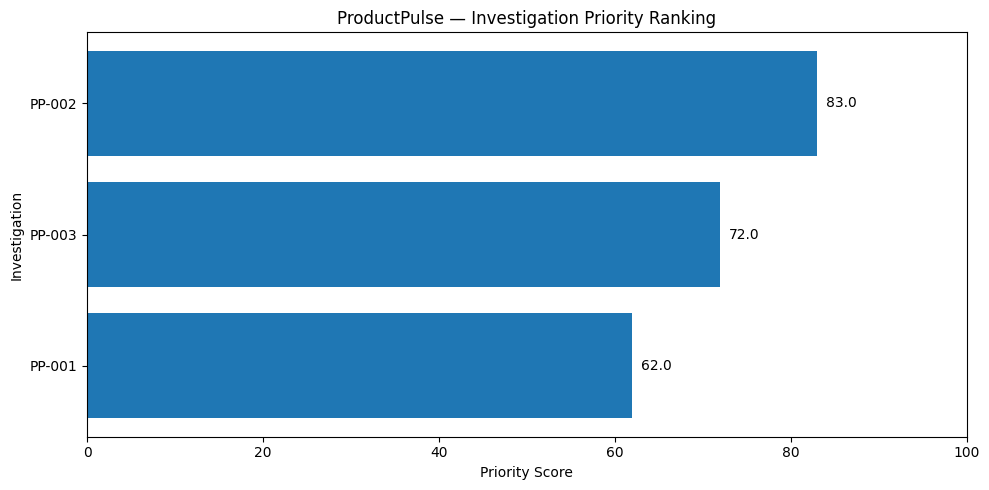

In [104]:
# PRODUCTPULSE — PRIORITY RANKING CHART

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.barh(
    investigation_ranking["investigation_id"],
    investigation_ranking["priority_score"]
)

plt.xlabel("Priority Score")
plt.ylabel("Investigation")
plt.title("ProductPulse — Investigation Priority Ranking")
plt.xlim(0, 100)
plt.gca().invert_yaxis()

for i, score in enumerate(investigation_ranking["priority_score"]):
    plt.text(score + 1, i, str(score), va="center")

plt.tight_layout()
plt.show()

# 9. Executive Dashboard & Results

## Bringing the Analysis Together

This section consolidates the key metrics and investigation outcomes into an executive-facing view.

The dashboard brings together:
- Overall platform activity and engagement metrics.
- Key behavioural patterns.
- Category-level investigation findings.
- Temporal anomalies and observed activity differences.
- Prioritized investigation candidates and their scores.

**Business purpose:** Present the most relevant findings in a concise format that helps stakeholders understand what was observed and where further investigation may be valuable.

**Interpretation note:** Dashboard metrics summarize the available dataset and preceding analyses. They should be interpreted alongside the methodology, data coverage, and limitations documented in this notebook.

In [105]:
# PRODUCTPULSE — EXECUTIVE DASHBOARD METRICS

priority_distribution = (
    investigation_ranking["priority"]
    .value_counts()
    .reindex(["Critical", "High", "Medium", "Low"], fill_value=0)
)

print("PRODUCTPULSE — EXECUTIVE OVERVIEW")
print("-" * 40)
print("Total investigations:", len(investigation_ranking))
print("Highest priority:", investigation_ranking.iloc[0]["investigation_id"])
print("Highest score:", investigation_ranking["priority_score"].max())
print("Average priority score:", round(
    investigation_ranking["priority_score"].mean(), 2
))

print("\nPriority distribution:")
display(priority_distribution.to_frame("investigation_count"))

print("\nInvestigation ranking:")
display(investigation_ranking)

PRODUCTPULSE — EXECUTIVE OVERVIEW
----------------------------------------
Total investigations: 3
Highest priority: PP-002
Highest score: 83.0
Average priority score: 72.33

Priority distribution:


,investigation_count
priority,
Critical,1
High,1
Medium,1
Low,0



Investigation ranking:


,investigation_id,investigation_name,priority_score,priority
0,PP-002,September 17 - Transaction Activity Anomaly,83.0,Critical
1,PP-003,Weekend - Lower Transaction Activity,72.0,High
2,PP-001,Category 642 - Low Downstream Activity,62.0,Medium


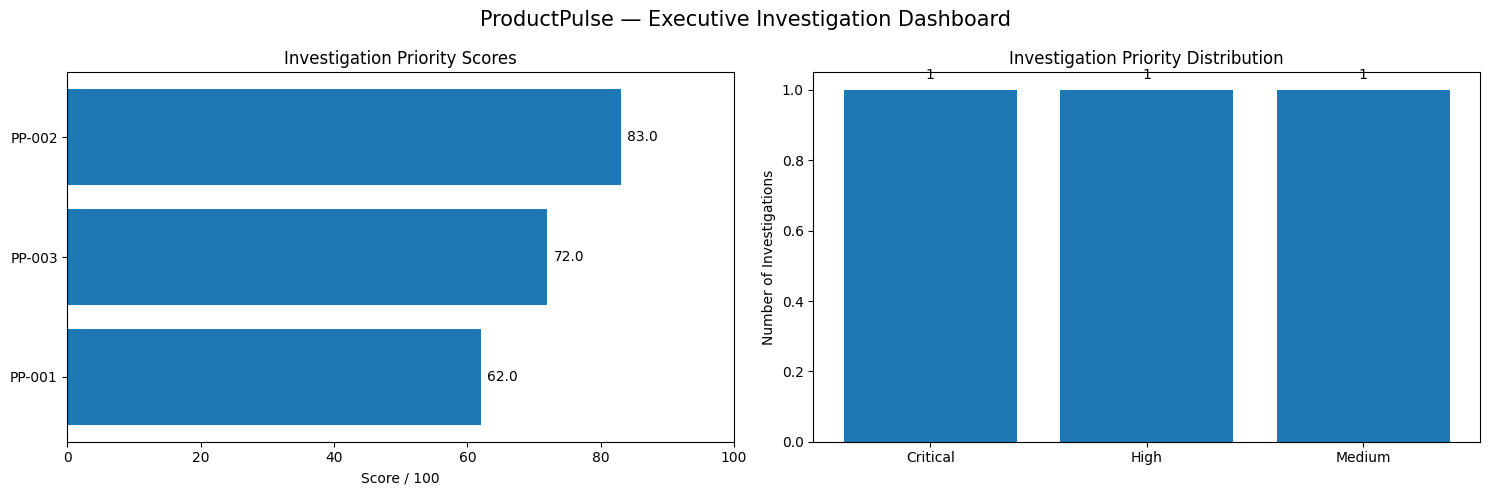

In [106]:
# PRODUCTPULSE — EXECUTIVE DASHBOARD VISUALIZATION

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Chart 1: Investigation priority scores
axes[0].barh(
    investigation_ranking["investigation_id"],
    investigation_ranking["priority_score"]
)

axes[0].set_title("Investigation Priority Scores")
axes[0].set_xlabel("Score / 100")
axes[0].set_xlim(0, 100)
axes[0].invert_yaxis()

for i, score in enumerate(investigation_ranking["priority_score"]):
    axes[0].text(score + 1, i, str(score), va="center")

# Chart 2: Priority distribution
priority_counts = priority_distribution[
    priority_distribution > 0
]

axes[1].bar(
    priority_counts.index,
    priority_counts.values
)

axes[1].set_title("Investigation Priority Distribution")
axes[1].set_ylabel("Number of Investigations")

for i, count in enumerate(priority_counts.values):
    axes[1].text(i, count + 0.03, str(count), ha="center")

fig.suptitle(
    "ProductPulse — Executive Investigation Dashboard",
    fontsize=15
)

plt.tight_layout()
plt.savefig(
    "productpulse_executive_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [107]:
# PRODUCTPULSE — EXPORT PROJECT OUTPUTS

investigation_ranking.to_csv(
    "productpulse_investigation_ranking.csv",
    index=False
)

pd.DataFrame([category_642_investigation]).to_csv(
    "productpulse_investigation_PP001.csv",
    index=False
)

print("Project outputs exported:")
print("1. productpulse_executive_dashboard.png")
print("2. productpulse_investigation_ranking.csv")
print("3. productpulse_investigation_PP001.csv")

Project outputs exported:
1. productpulse_executive_dashboard.png
2. productpulse_investigation_ranking.csv
3. productpulse_investigation_PP001.csv


# 10. Key Findings, Recommendations & Limitations

## Key Findings

1. **User engagement is heavily concentrated in views:** Views account for the majority of recorded platform events, while add-to-cart and transaction events represent much smaller shares.

2. **Cart and transaction activity show meaningful overlap:** A substantial proportion of matched visitor-product pairs with cart activity also have a transaction event. However, this overlap is not a formal conversion rate.

3. **Weekend transaction activity is relatively lower:** Transactions per 1,000 views are lower on weekends than on weekdays in the observed dataset.

4. **September 17 shows an unusual activity decline:** Transaction activity was substantially below the comparison baseline for other Thursdays. This warrants further investigation into possible operational, payment, tracking, or traffic-related explanations.

5. **Category 642 warrants further investigation:** It recorded substantial viewing activity but very little cart and transaction activity. Historical product-category reassignment complicates interpretation of this pattern.

## Recommended Next Steps

- Investigate the September 17 anomaly using checkout logs, payment gateway responses, and event-tracking records.
- Examine weekend traffic sources, visitor composition, and purchasing patterns.
- Investigate Category 642 through product relevance, pricing, availability, product-page quality, and category classification.
- Validate event instrumentation and historical category mappings before making operational decisions.

## Limitations

- The dataset covers a historical period from May to September 2015 and may not represent current customer behaviour.
- The available event data does not provide a complete, reliable session-level purchase funnel.
- Visitor and visitor-product event overlaps should not be interpreted as formal conversion or abandonment rates.
- Historical category information has incomplete event coverage.
- Category reassignment makes some category-level comparisons difficult.
- Observational patterns and temporal associations do not establish causation.
- Investigation priority scores depend on analyst-assigned ratings, weights, and thresholds.

## Final Takeaway

ProductPulse demonstrates an evidence-driven approach to product investigation: identify behavioural patterns, validate the underlying data, investigate unusual findings, assess potential business significance, and prioritize the next actions.

The objective is not to claim that every observed pattern represents a confirmed product issue, but to demonstrate how data can guide better product and business decisions.